In [1]:
import sys, torch
from packaging.version import Version

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torch CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if sys.version_info < (3, 12):
    raise RuntimeError("SAM 3.1 official setup requires Python 3.12 or newer. Select a current Colab runtime.")
if Version(torch.__version__.split('+')[0]) < Version("2.7.0"):
    raise RuntimeError("PyTorch 2.7+ is required. See the install cell below, install the current official CUDA wheel, then restart the runtime.")
if not torch.cuda.is_available():
    raise RuntimeError("GPU is not enabled. Select Runtime → Change runtime type → T4 GPU.")
if torch.version.cuda and Version(torch.version.cuda) < Version("12.6"):
    raise RuntimeError("The installed PyTorch CUDA runtime is older than 12.6. Install the official CUDA 12.8 PyTorch wheel below, then restart the runtime.")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Torch CUDA runtime: 13.0
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56


In [2]:
%cd /content
!git clone https://github.com/facebookresearch/sam3.git
%cd /content/sam3
!pip -q install -e .
!pip -q install matplotlib pandas tqdm pillow

/content
Cloning into 'sam3'...
remote: Enumerating objects: 1525, done.
remote: Counting objects: 100% (68/68), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 1525 (delta 42), reused 29 (delta 29), pack-reused 1457 (from 3)
Receiving objects: 100% (1525/1525), 60.72 MiB | 18.30 MiB/s, done.
Resolving deltas: 100% (597/597), done.
/content/sam3
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for sam3 (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently tak

In [3]:
from pathlib import Path
%cd /content
if not Path('/content/sam3').exists():
    !git clone https://github.com/facebookresearch/sam3.git
%cd /content/sam3
!pip -q install -e .
!pip -q install matplotlib pandas tqdm pillow


/content
/content/sam3
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for sam3 (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
xarray-einstats 0.11.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jax 0.11.1 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.11.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tifffile 2026.10.15 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
pytensor 2.38.3 requires numpy>=2.0, but you have numpy 1.26.4 whi

In [8]:
import zipfile
from pathlib import Path
from google.colab import drive

# Mount Google Drive to access the dataset
drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/egg_cv_assignment')
ZIP_PATH = PROJECT_DIR / 'egg.v1i.folder.zip'

EXTRACT_DIR = Path('/content/egg_dataset_extracted')
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

if not ZIP_PATH.exists():
    raise FileNotFoundError(f'Could not find the dataset ZIP at {ZIP_PATH}. Make sure Google Drive is mounted correctly and the file exists.')

with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
image_paths = sorted(
    p for p in EXTRACT_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

print('Images found:', len(image_paths))
for p in image_paths[:10]:
    print(p.relative_to(EXTRACT_DIR))

if not image_paths:
    raise RuntimeError('No images found. Check the ZIP file and extraction path.')

Mounted at /content/drive
Images found: 110
test/egg/not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg
test/egg/not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg
test/egg/not_damaged_14_jpg.rf.dc96559078b03433d2b65e5055904af1.jpg
test/egg/not_damaged_152_jpg.rf.a57edb18d395ce87e23f7abccbd1ad69.jpg
test/egg/not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74f1bc143a8.jpg
test/egg/not_damaged_161_jpg.rf.fd216aa5e11e147fc1527478cceae94e.jpg
test/egg/not_damaged_1_jpg.rf.d74c98a14f068b48c1f58fd573361f1f.jpg
test/egg/not_damaged_30_jpg.rf.48e9261777355fe67139ac1c5eae596b.jpg
test/egg/not_damaged_43_jpg.rf.66c31342150e751c30214786e72c8683.jpg
test/egg/not_damaged_4_jpg.rf.36c78b63ea4710d9642651ac3292fd58.jpg


In [10]:
from huggingface_hub import login

# Request access to https://huggingface.co/facebook/sam3.1 before running this cell.
# Use a Hugging Face READ token. The token is not stored in this notebook source.
login()

In [11]:
import torch
from sam3.model_builder import build_sam3_image_model, download_ckpt_from_hf
from sam3.model.sam3_image_processor import Sam3Processor

# Explicitly download the SAM 3.1 checkpoint (not the older SAM 3 checkpoint).
checkpoint_path = download_ckpt_from_hf(version='sam3.1')
print('Checkpoint downloaded to:', checkpoint_path)

DEVICE = 'cuda'
model = build_sam3_image_model(
    checkpoint_path=checkpoint_path,
    load_from_HF=False,
    device=DEVICE,
    eval_mode=True,
    enable_segmentation=True,
)

CONFIDENCE_THRESHOLD = 0.50
PROMPT = 'egg'
processor = Sam3Processor(
    model,
    device=DEVICE,
    confidence_threshold=CONFIDENCE_THRESHOLD,
)

AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print('SAM 3.1 image model loaded successfully.')
print('Autocast dtype:', AMP_DTYPE)

config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

sam3.1_multiplex.pt: reconstructing file:   0%|          |  0.00B / 3.50GB            

sam3.1_multiplex.pt: downloading bytes:           |  0.00B            

Checkpoint downloaded to: /root/.cache/huggingface/hub/models--facebook--sam3.1/snapshots/daa63191845a41281374e725f4c9e51c7a824460/sam3.1_multiplex.pt
loaded /root/.cache/huggingface/hub/models--facebook--sam3.1/snapshots/daa63191845a41281374e725f4c9e51c7a824460/sam3.1_multiplex.pt and found missing and/or unexpected keys:
missing_keys=['backbone.vision_backbone.convs.3.conv_1x1.weight', 'backbone.vision_backbone.convs.3.conv_1x1.bias', 'backbone.vision_backbone.convs.3.conv_3x3.weight', 'backbone.vision_backbone.convs.3.conv_3x3.bias']
SAM 3.1 image model loaded successfully.
Autocast dtype: torch.bfloat16


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
import json, time

OUTPUT_DIR = PROJECT_DIR / 'sam3_1_outputs'
MASK_DIR = OUTPUT_DIR / 'instance_masks'
COMBINED_DIR = OUTPUT_DIR / 'combined_masks'
OVERLAY_DIR = OUTPUT_DIR / 'overlays'
META_DIR = OUTPUT_DIR / 'metadata'
for folder in [MASK_DIR, COMBINED_DIR, OVERLAY_DIR, META_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

PALETTE = [
    (255, 60, 60), (40, 180, 255), (60, 220, 100),
    (255, 180, 30), (190, 90, 255), (30, 220, 210),
]

def segment_image(image: Image.Image):
    'Return per-instance binary masks, xyxy boxes and confidence scores.'
    image = image.convert('RGB')
    state = processor.set_image(image)
    result = processor.set_text_prompt(state=state, prompt=PROMPT)

    masks_t = result['masks'].detach().cpu()
    # Official processor returns masks as [N, 1, H, W]. Convert to [N, H, W].
    if masks_t.ndim == 4 and masks_t.shape[1] == 1:
        masks_t = masks_t[:, 0]
    masks = masks_t.float().numpy().astype(bool)

    # Cast to standard float32 before calling .numpy() to prevent BFloat16 type errors
    boxes = result['boxes'].detach().cpu().float().numpy()   # xyxy in original image pixels
    scores = result['scores'].detach().cpu().float().numpy()
    return masks, boxes, scores


def make_overlay(image: Image.Image, masks, boxes=None, scores=None, alpha=0.42):
    'Draw a transparent colored overlay and SAM bounding boxes.'
    base = np.asarray(image.convert('RGB')).copy()
    for idx, mask in enumerate(masks):
        color = np.asarray(PALETTE[idx % len(PALETTE)], dtype=np.float32)
        base[mask] = (base[mask] * (1 - alpha) + color * alpha).astype(np.uint8)

    out = Image.fromarray(base)
    draw = ImageDraw.Draw(out)
    if boxes is not None:
        for idx, box in enumerate(boxes):
            x1, y1, x2, y2 = [int(round(v)) for v in box]
            color = PALETTE[idx % len(PALETTE)]
            draw.rectangle((x1, y1, x2, y2), outline=color, width=3)
            label = f"egg {idx + 1}"
            if scores is not None:
                label += f" {float(scores[idx]):.2f}"
            draw.text((x1, max(0, y1 - 16)), label, fill=color)
    return out

print('Output directory:', OUTPUT_DIR)

Output directory: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs


Image: not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg
Detected egg instances: 1
Scores: [0.9769999980926514]


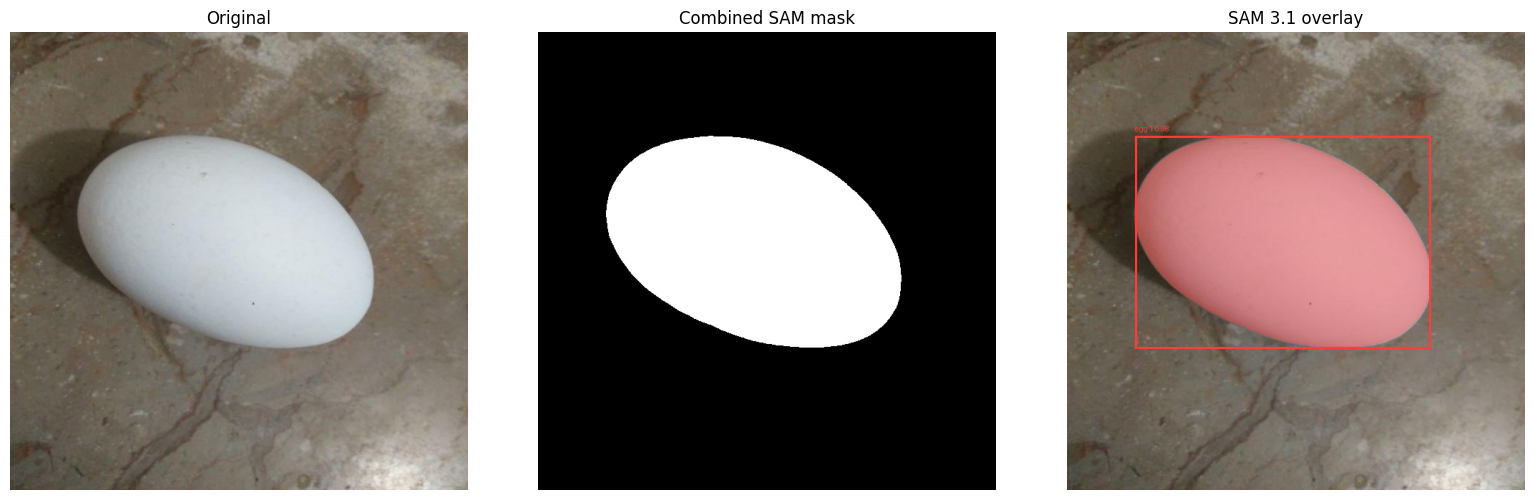

In [13]:
test_path = image_paths[0]
test_image = Image.open(test_path).convert('RGB')

# Run the inference with autocast to resolve the BFloat16 vs Float mismatch
with torch.amp.autocast('cuda', dtype=AMP_DTYPE):
    test_masks, test_boxes, test_scores = segment_image(test_image)

test_overlay = make_overlay(test_image, test_masks, test_boxes, test_scores)

print('Image:', test_path.name)
print('Detected egg instances:', len(test_masks))
print('Scores:', np.round(test_scores, 3).tolist())

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(test_image); axes[0].set_title('Original')
axes[1].imshow(np.any(test_masks, axis=0) if len(test_masks) else np.zeros((test_image.height, test_image.width)), cmap='gray'); axes[1].set_title('Combined SAM mask')
axes[2].imshow(test_overlay); axes[2].set_title('SAM 3.1 overlay')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

In [14]:
records = []
errors = []
start_all = time.time()

for image_path in tqdm(image_paths, desc='SAM 3.1 segmentation'):
    relative = image_path.relative_to(EXTRACT_DIR)
    image = None
    try:
        image = Image.open(image_path).convert('RGB')

        # Run the model with autocast to resolve the BFloat16 vs Float mismatch
        with torch.amp.autocast('cuda', dtype=AMP_DTYPE):
            masks, boxes, scores = segment_image(image)

        h, w = np.asarray(image).shape[:2]

        # Keep the original folder structure to prevent filename collisions.
        per_image_mask_dir = MASK_DIR / relative.parent / relative.stem
        per_image_mask_dir.mkdir(parents=True, exist_ok=True)
        combined_path = COMBINED_DIR / relative.parent / f'{relative.stem}.png'
        overlay_path = OVERLAY_DIR / relative.parent / f'{relative.stem}.jpg'
        meta_path = META_DIR / relative.parent / f'{relative.stem}.json'
        combined_path.parent.mkdir(parents=True, exist_ok=True)
        overlay_path.parent.mkdir(parents=True, exist_ok=True)
        meta_path.parent.mkdir(parents=True, exist_ok=True)

        if len(masks) > 0:
            combined = np.any(masks, axis=0).astype(np.uint8) * 255
        else:
            combined = np.zeros((h, w), dtype=np.uint8)
        Image.fromarray(combined, mode='L').save(combined_path)

        for idx, mask in enumerate(masks):
            instance_path = per_image_mask_dir / f'egg_{idx + 1:02d}.png'
            Image.fromarray(mask.astype(np.uint8) * 255, mode='L').save(instance_path)
            x1, y1, x2, y2 = [float(v) for v in boxes[idx]]
            records.append({
                'image': str(relative),
                'instance_id': idx + 1,
                'score': float(scores[idx]),
                'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2,
                'mask_area_pixels': int(mask.sum()),
                'mask_path': str(instance_path.relative_to(OUTPUT_DIR)),
                'combined_mask_path': str(combined_path.relative_to(OUTPUT_DIR)),
            })

        if len(masks) == 0:
            records.append({
                'image': str(relative), 'instance_id': None, 'score': None,
                'x1': None, 'y1': None, 'x2': None, 'y2': None,
                'mask_area_pixels': 0, 'mask_path': None,
                'combined_mask_path': str(combined_path.relative_to(OUTPUT_DIR)),
            })

        overlay = make_overlay(image, masks, boxes, scores)
        overlay.save(overlay_path, quality=92)

        with open(meta_path, 'w') as f:
            json.dump({
                'source_image': str(relative),
                'model': 'Meta SAM 3.1 open-weight checkpoint',
                'prompt': PROMPT,
                'confidence_threshold': CONFIDENCE_THRESHOLD,
                'image_width': w,
                'image_height': h,
                'num_instances': int(len(masks)),
                'scores': [float(x) for x in scores],
            }, f, indent=2)

    except Exception as exc:
        errors.append({'image': str(image_path), 'error': repr(exc)})
        print(f'ERROR on {image_path.name}: {exc}')

    finally:
        del image

manifest = pd.DataFrame(records)
manifest_path = OUTPUT_DIR / 'sam3_instance_manifest.csv'
manifest.to_csv(manifest_path, index=False)

with open(OUTPUT_DIR / 'errors.json', 'w') as f:
    json.dump(errors, f, indent=2)

elapsed = time.time() - start_all
print(f'Processed {len(image_paths) - len(errors)} / {len(image_paths)} images in {elapsed / 60:.2f} minutes.')
print('Images with processing errors:', len(errors))

if not manifest.empty and 'instance_id' in manifest.columns:
    print('Detected instances:', int(manifest['instance_id'].notna().sum()))
else:
    print('Detected instances: 0')
print('Manifest:', manifest_path)

SAM 3.1 segmentation:   0%|          | 0/110 [00:00<?, ?it/s]

/tmp/ipykernel_649/2371276566.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(combined, mode='L').save(combined_path)
/tmp/ipykernel_649/2371276566.py:35: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(mask.astype(np.uint8) * 255, mode='L').save(instance_path)


Processed 110 / 110 images in 10.92 minutes.
Images with processing errors: 0
Detected instances: 137
Manifest: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/sam3_instance_manifest.csv


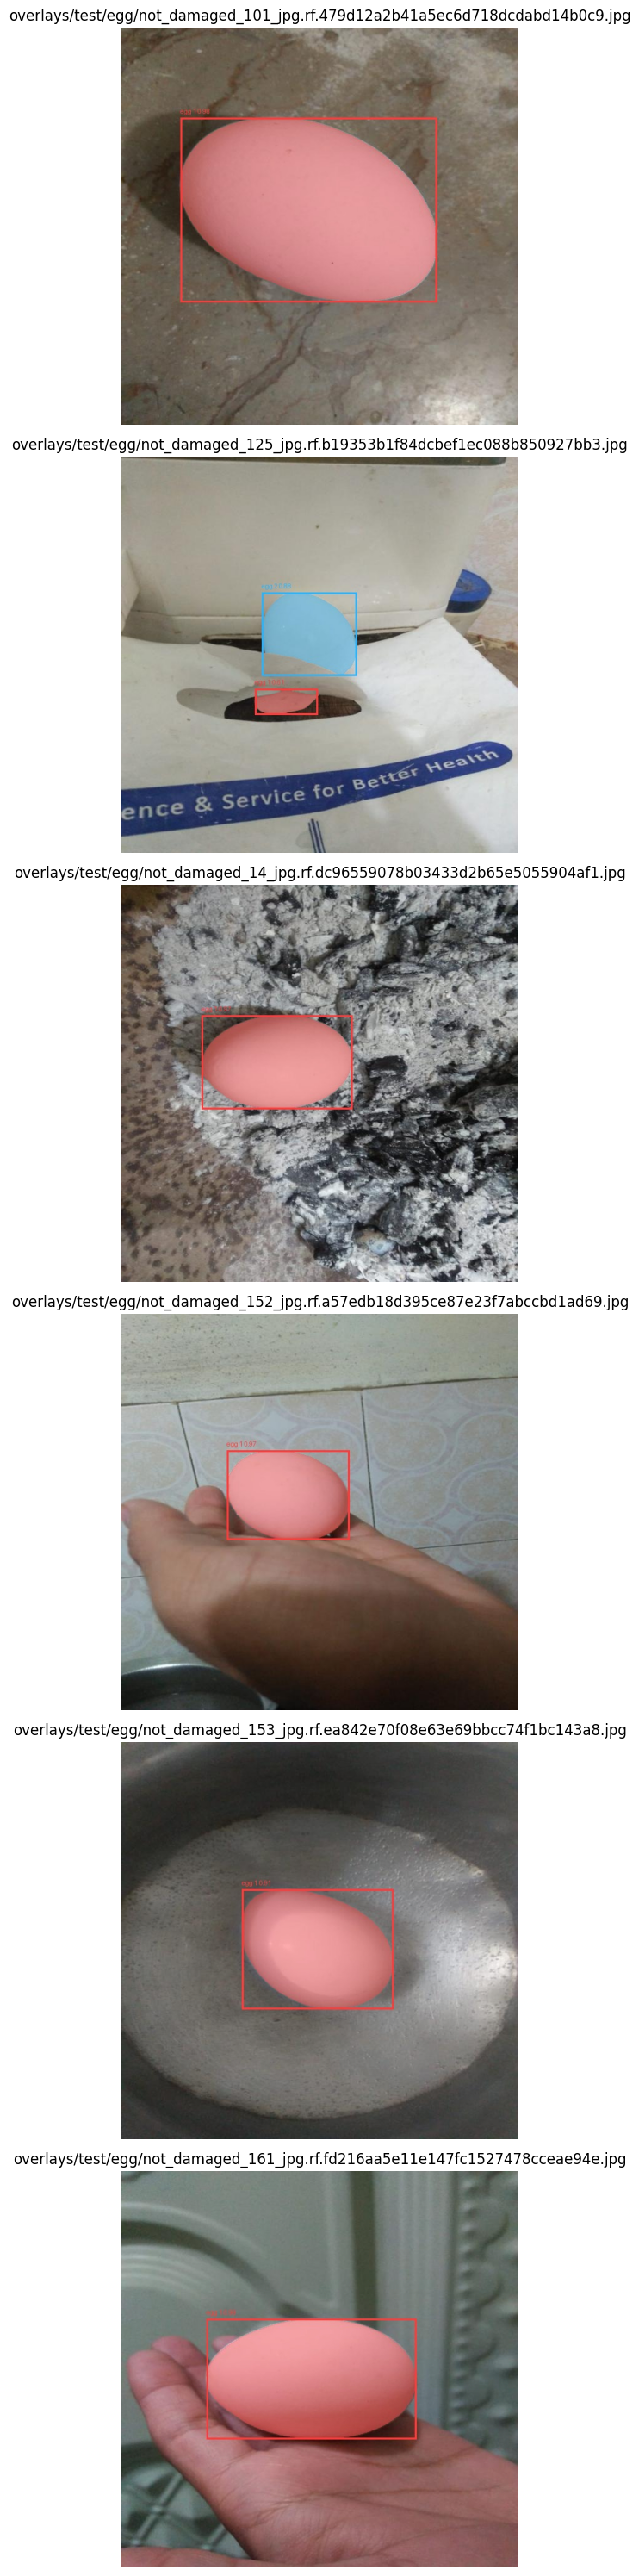

Combined masks: 110
Instance mask files: 137
Overlay images: 110
Saved to Google Drive: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs


In [15]:
# Show a few overlays from the output folder.
overlay_paths = sorted(OVERLAY_DIR.rglob('*.jpg'))[:6]
if not overlay_paths:
    print('No overlays found.')
else:
    fig, axes = plt.subplots(len(overlay_paths), 1, figsize=(8, 5 * len(overlay_paths)))
    if len(overlay_paths) == 1:
        axes = [axes]
    for ax, path in zip(axes, overlay_paths):
        ax.imshow(Image.open(path))
        ax.set_title(str(path.relative_to(OUTPUT_DIR)))
        ax.axis('off')
    plt.tight_layout(); plt.show()

print('Combined masks:', len(list(COMBINED_DIR.rglob('*.png'))))
print('Instance mask files:', len(list(MASK_DIR.rglob('*.png'))))
print('Overlay images:', len(list(OVERLAY_DIR.rglob('*.jpg'))))
print('Saved to Google Drive:', OUTPUT_DIR)